# Source profiling and grain validation
Original data is preserved. Null outcomes, repeated geolocations and multiple reviews are handled explicitly.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
def report(name): return pd.read_csv(ROOT / 'reports' / (name + '.csv'))
def metadata(name): return json.loads((ROOT / 'reports' / (name + '.json')).read_text())
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
profile = metadata('source_profile')
pd.DataFrame([{'table': k, 'rows': v['rows'], 'duplicate_keys': v['duplicate_keys'], 'exact_duplicates': v['exact_duplicate_rows']} for k,v in profile.items()])

,table,rows,duplicate_keys,exact_duplicates
0,orders,99441,0.0,0
1,order_items,112650,0.0,0
2,customers,99441,0.0,0
3,sellers,3095,0.0,0
4,products,32951,0.0,0
5,order_payments,103886,0.0,0
6,order_reviews,99224,NaN,0
7,geolocation,1000163,NaN,261831
8,category_translation,71,0.0,0


In [3]:
pd.DataFrame({k:v['nulls'] for k,v in profile.items()}).fillna('').T

C:\Users\SYS\AppData\Local\Temp\ipykernel_12916\1069568271.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame({k:v['nulls'] for k,v in profile.items()}).fillna('').T


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,product_category_name_english
orders,0.0,0.0,0.0,0.0,160.0,1783.0,2965.0,0.0,,,...,,,,,,,,,,
order_items,0.0,,,,,,,,0.0,0.0,...,,,,,,,,,,
customers,,0.0,,,,,,,,,...,,,,,,,,,,
sellers,,,,,,,,,,,...,,,,,,,,,,
products,,,,,,,,,,0.0,...,,,,,,,,,,
order_payments,0.0,,,,,,,,,,...,,,,,,,,,,
order_reviews,0.0,,,,,,,,,,...,87656.0,58247.0,0.0,0.0,,,,,,
geolocation,,,,,,,,,,,...,,,,,0.0,0.0,0.0,0.0,0.0,
category_translation,,,,,,,,,,,...,,,,,,,,,,0.0


In [4]:
metadata('data_quality')

{'total_orders': 99441,
 'ineligible_punctuality': 2971,
 'delivered_missing_actual': 8,
 'carrier_before_purchase': 166,
 'delivery_before_carrier': 23,
 'approval_before_purchase': 0,
 'multi_seller_orders': 1278,
 'multi_item_orders': 9803,
 'multi_payment_orders': 2961,
 'distance_missing': 775,
 'weight_missing': 791,
 'promised_missing': 0,
 'missing_seller_refs': 0,
 'missing_product_refs': 0,
 'geolocation_outside_brazil_bbox': 42,
 'negative_item_amounts': 0,
 'invalid_product_dimensions': 4,
 'invalid_zip_prefixes': 0}

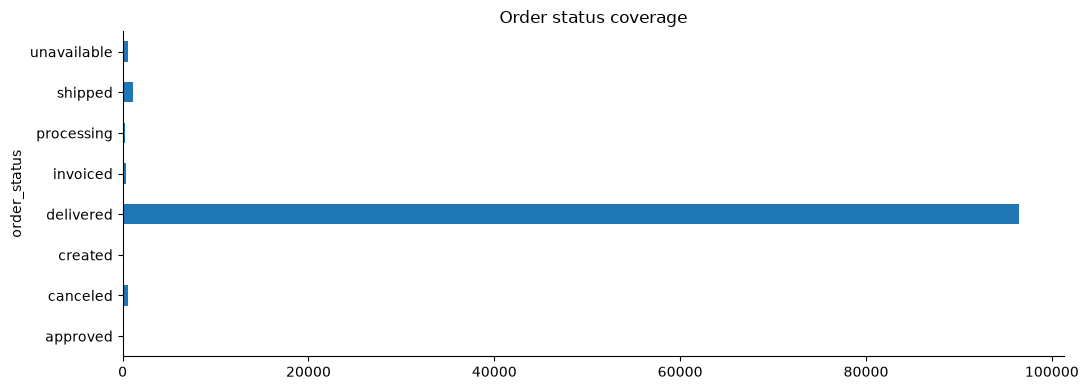

In [5]:
status=report('status_coverage')
status.set_index('order_status')['orders'].plot.barh(title='Order status coverage'); plt.tight_layout(); plt.show()

In [6]:
orders=pd.read_parquet(ROOT/'data/processed/fct_order.parquet')
items=pd.read_parquet(ROOT/'data/processed/fct_order_item.parquet')
assert orders.order_id.is_unique
assert abs(float(pd.to_numeric(orders.item_value).sum())-float(pd.to_numeric(items.price).sum()))<.01
print('Source grain and monetary reconciliation passed')

Source grain and monetary reconciliation passed


See reports/source_profile.json for every column, null count and source SHA-256. Known timestamp anomalies remain in the quality report.